# 05 — Validation evidence and paired gingival ROI preparation

## Research question
Can local detail, surrounding context and ordered labels improve gingival appearance grading?
This notebook establishes the data and error evidence before building the CNN baselines.
It reads completed v4 detector results, prepares train/validation crops, and preserves the parent split.
It does not evaluate the test split or train a model.

## Protocol
1. Verify the parent split and image/label SHA-256 values.
2. Inspect aggregate validation evidence and saved detector examples.
3. Convert each annotated gingival box to a local crop and a 1.5× context crop.
4. Resize to 224×224 with explicit constant padding, save both views and provenance.
5. Inspect class balance, native ROI sizes, examples and the limitations of the derived task.

Three labels denote **local appearance groups**, not patient-level diagnoses.
All crops from one source image retain its original split and group.

In [1]:
from pathlib import Path
import json, inspect, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/configs/roi.json").is_file())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display
from dentalselfie.roi import prepare_rois, audit_training_reports
REPORT = ROOT / "docs/reports/roi_preparation"
OUTPUT = ROOT / "data/processed/gum_roi_v1"
DATASET = ROOT / "data/processed/gum/dataset"
REPORT.mkdir(parents=True, exist_ok=True)
config = json.loads((ROOT / "src/configs/roi.json").read_text())
display(pd.Series(config, name="ROI protocol"))

protocol                                        gingival-roi-context-v1
splits                                                     [train, val]
size                                                                224
context_multiplier                                                  1.5
padding_rgb                                             [128, 128, 128]
jpeg_quality                                                         95
jpeg_subsampling                                                      0
classes               [no_visible_inflammation, mild_inflammation, m...
notes                 Central ROI label only. Context is auxiliary. ...
Name: ROI protocol, dtype: object

## 1. Completed detector evidence

The final best-checkpoint validation console table supplies rounded per-class metrics.
The CSV history describes epoch development. Neither provides a complete saved per-instance
prediction table. We therefore do not estimate exact localization/classification error shares here.
Saved confusion matrices and example mosaics support qualitative inspection only.

,experiment,epochs,seconds,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
0,E0,22,258.488317,0.408104,0.695632,0.535213,0.292851
1,E1,19,314.381251,0.438708,0.625308,0.543716,0.286981


,experiment,class_name,images,instances,precision,recall,ap50,ap50_95,provenance
0,E0,no_visible_inflammation,23,49,0.142,0.2650,0.163,0.0997,Final best-checkpoint validation console table...
1,E0,mild_inflammation,132,932,0.554,0.9250,0.693,0.3780,Final best-checkpoint validation console table...
2,E0,marked_inflammation,133,939,0.529,0.8970,0.750,0.4010,Final best-checkpoint validation console table...
3,E1,no_visible_inflammation,23,49,0.231,0.0408,0.177,0.1070,Final best-checkpoint validation console table...
4,E1,mild_inflammation,132,932,0.587,0.8810,0.687,0.3590,Final best-checkpoint validation console table...
5,E1,marked_inflammation,133,939,0.498,0.9540,0.767,0.3950,Final best-checkpoint validation console table...


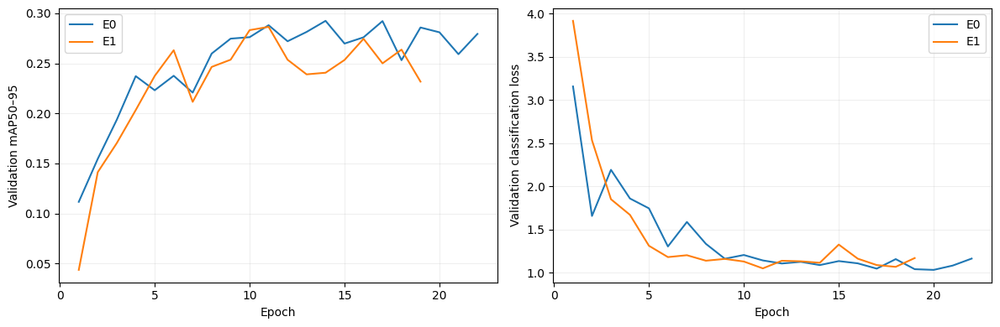

In [2]:
overall, classes = audit_training_reports(ROOT, REPORT)
display(overall)
display(classes)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for experiment in ["E0", "E1"]:
    h = pd.read_csv(REPORT / f"{experiment}_gum_history.csv")
    axes[0].plot(h["epoch"], h["metrics/mAP50-95(B)"], label=experiment)
    axes[1].plot(h["epoch"], h["val/cls_loss"], label=experiment)
axes[0].set(xlabel="Epoch", ylabel="Validation mAP50–95")
axes[1].set(xlabel="Epoch", ylabel="Validation classification loss")
for ax in axes: ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(REPORT / "detector_curves.png", dpi=150)
plt.show()

E0 saved validation evidence; images are not a new prediction run


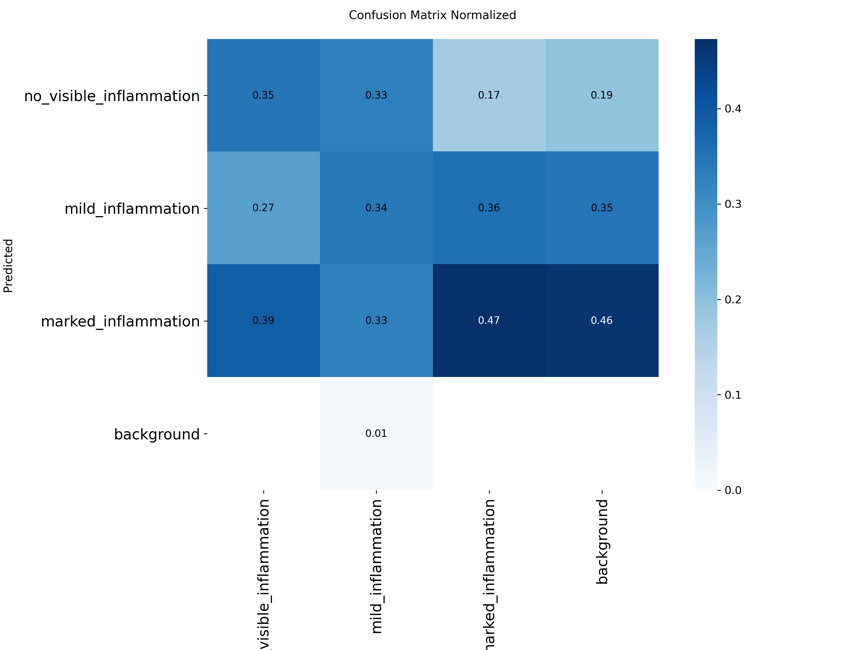

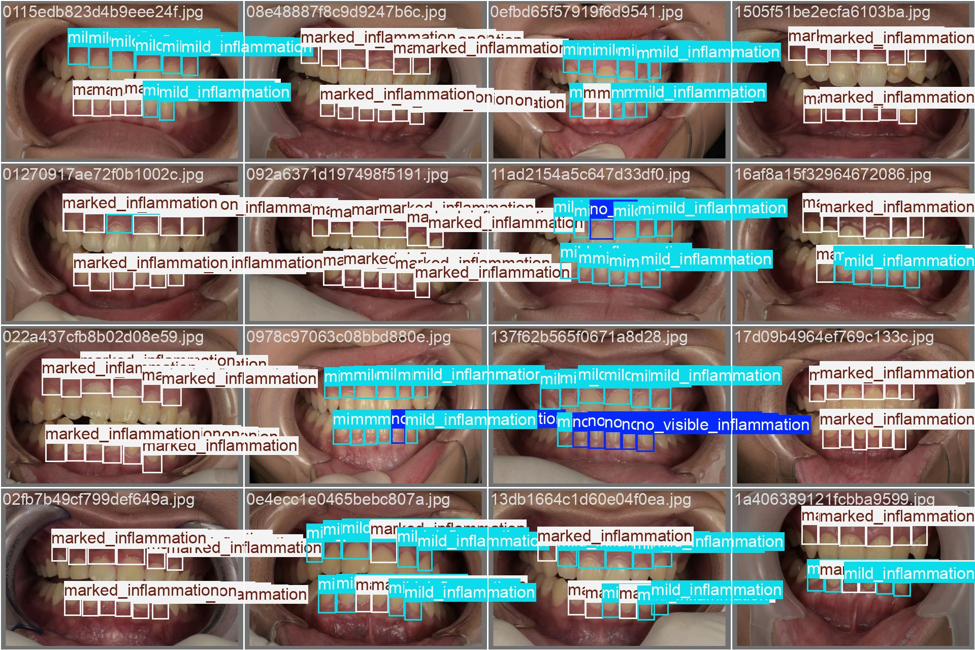

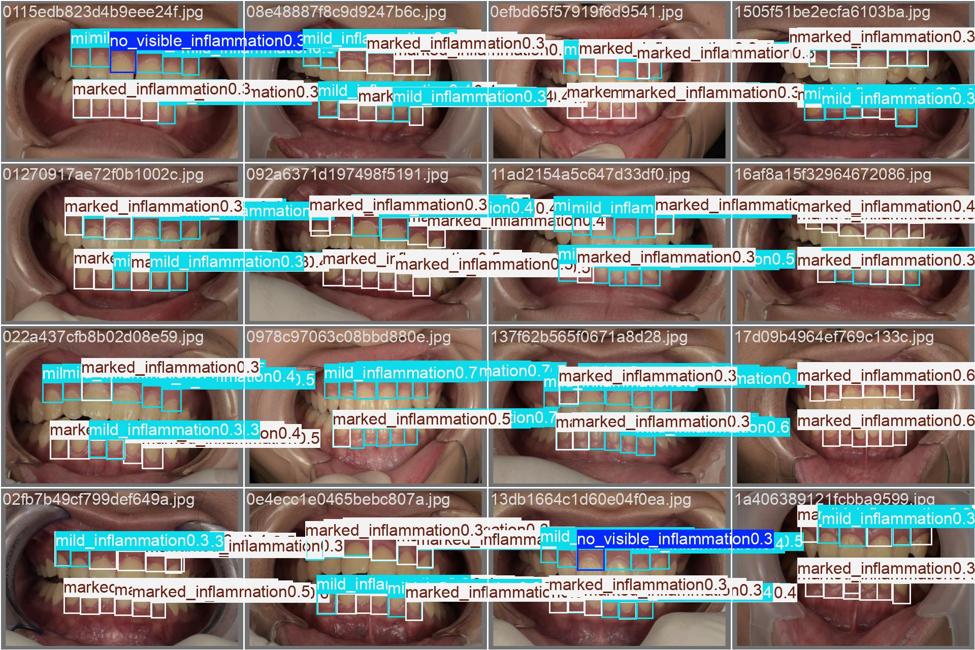

E1 saved validation evidence; images are not a new prediction run


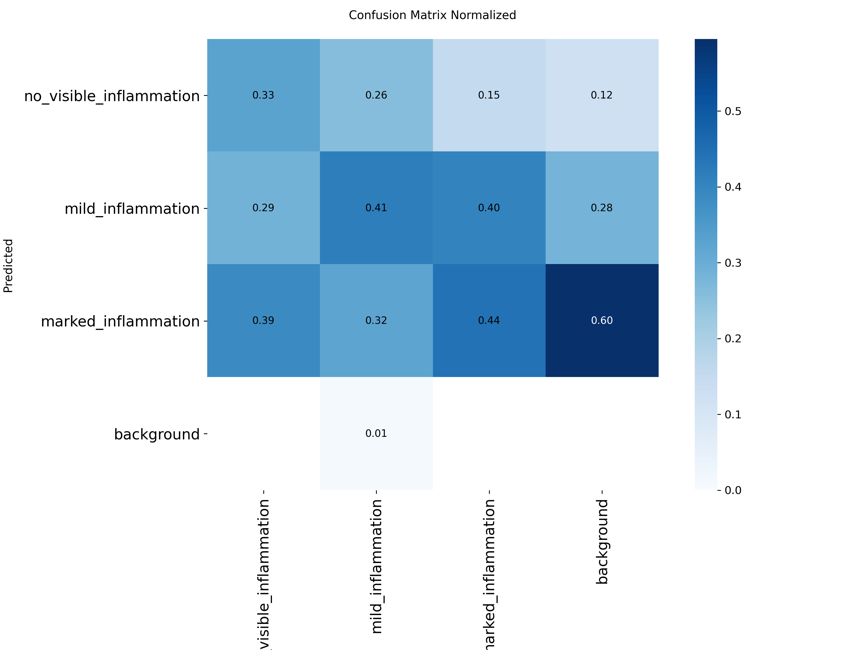

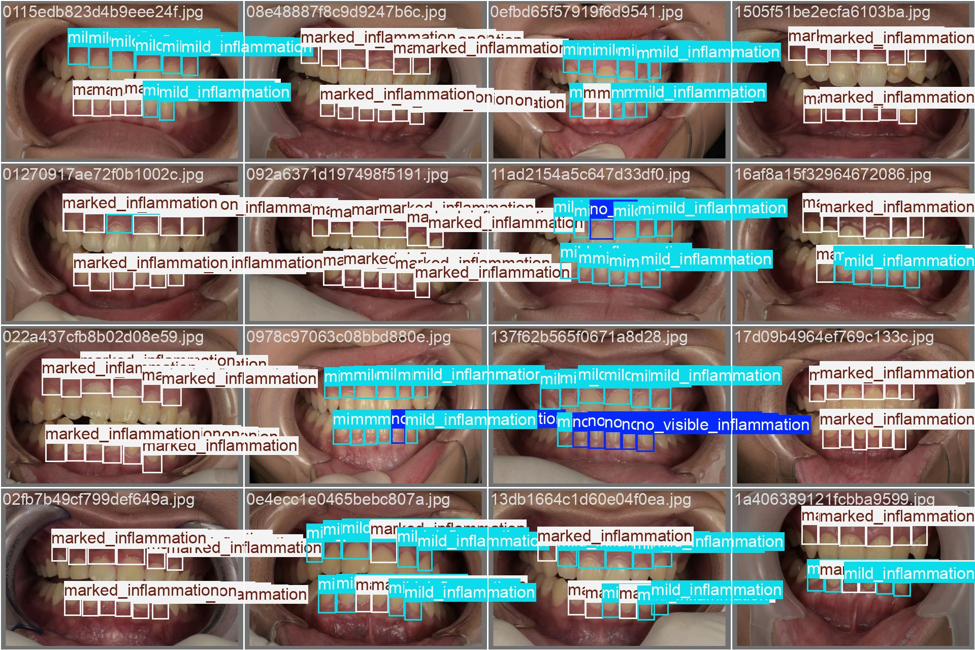

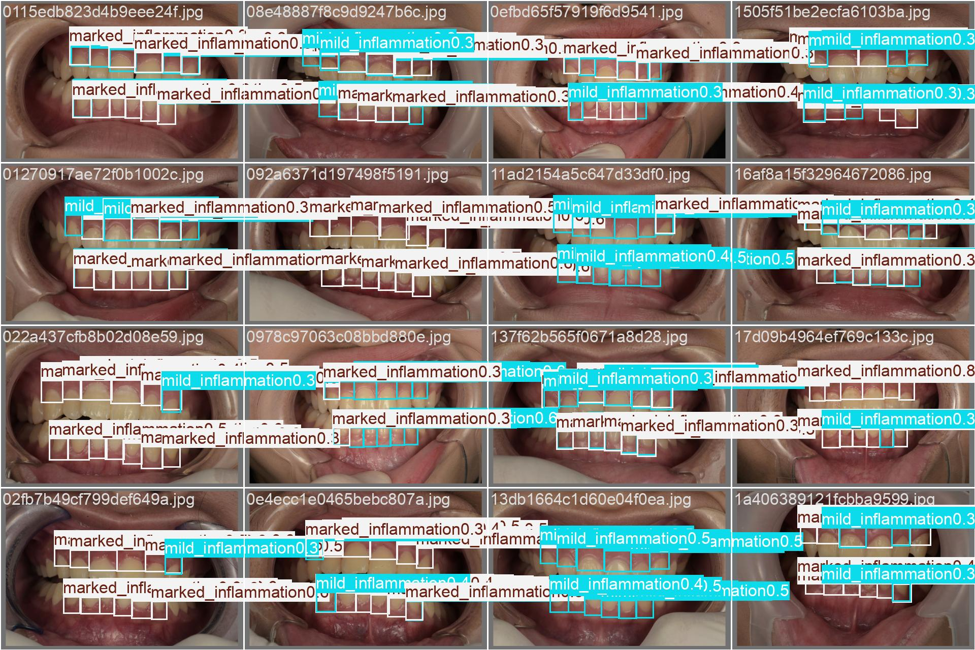

In [3]:
for experiment in ["E0", "E1"]:
    source = ROOT / "data/runs" / f"{experiment}_full_v4/experiments" / f"{experiment}_gum_seed42"
    print(experiment, "saved validation evidence; images are not a new prediction run")
    for name in ["confusion_matrix_normalized.png", "val_batch0_labels.jpg", "val_batch0_pred.jpg"]:
        with Image.open(source / name) as im:
            preview = im.copy(); preview.thumbnail((1000, 650)); display(preview)

## 2. Deterministic derived data

Only train and validation rows are processed. Parent image and label checksums are checked before cropping.
Local integer bounds use floor/ceil around the original floating-point rectangle.
The wider context can exceed the image: its padding is explicitly stored in the manifest.
Context preserves the **central ROI's** label; it is not labelled as a whole context region.
No augmentation, class resampling or new clinical labels are introduced here.

The shared function processes each image once, creates its two views, records hashes, and checks
parent/group isolation. On rerun it verifies existing crop hashes rather than overwriting them.

signature             {'protocol': 'gingival-roi-context-v1', 'confi...
manifest_sha256       8ed4c05240a2d23e6c254ee74adf13af48ff45a4418f1e...
crops                                                             10889
views                                                             21778
parents                                                             907
counts                [{'split': 'train', 'class_name': 'marked_infl...
test_images_opened                                                    0
independence          Parent/group isolation inherited; no patient i...
Name: Verified preparation receipt, dtype: object

,crop_id,parent_id,group_id,split,class_id,class_name,image_path,parent_sha256,label_sha256,box_index,box_width,box_height,local_path,local_bounds,local_padding,local_sha256,context_path,context_bounds,context_padding,context_sha256
0,00294ba7a545d3ec9455_00,00294ba7a545d3ec9455,gum:constraint:00294ba7a545d3ec9455,train,2,marked_inflammation,images/train/00294ba7a545d3ec9455.jpg,7b0ad3b26989bd24e56fc59868ee7924d6cb68fe9e1e47...,28e3ef080b66b3ce3a097f2faa7baae2ee909f04fbfd5e...,0,124.34816,108.314528,train/local/00294ba7a545d3ec9455_00.jpg,"[255, 275, 381, 384]","[0, 0, 0, 0]",1c30c1c160d906dd935de1acc9345d6335be9199d5d2ac...,train/context/00294ba7a545d3ec9455_00.jpg,"[224, 248, 412, 411]","[0, 0, 0, 0]",5b4ffdb3d27c27b19af1ae45c0bbf8c110fd133d43e79d...
1,00294ba7a545d3ec9455_01,00294ba7a545d3ec9455,gum:constraint:00294ba7a545d3ec9455,train,2,marked_inflammation,images/train/00294ba7a545d3ec9455.jpg,7b0ad3b26989bd24e56fc59868ee7924d6cb68fe9e1e47...,28e3ef080b66b3ce3a097f2faa7baae2ee909f04fbfd5e...,1,108.34816,129.699542,train/local/00294ba7a545d3ec9455_01.jpg,"[373, 268, 483, 399]","[0, 0, 0, 0]",0272f2eb507a7bf783f0cf1088134c8ca8789928610ae2...,train/context/00294ba7a545d3ec9455_01.jpg,"[346, 236, 510, 431]","[0, 0, 0, 0]",1bd71fe89d193921bae4bcc90fac0b6cfad046bc221f03...
2,00294ba7a545d3ec9455_02,00294ba7a545d3ec9455,gum:constraint:00294ba7a545d3ec9455,train,2,marked_inflammation,images/train/00294ba7a545d3ec9455.jpg,7b0ad3b26989bd24e56fc59868ee7924d6cb68fe9e1e47...,28e3ef080b66b3ce3a097f2faa7baae2ee909f04fbfd5e...,2,168.52224,132.481020,train/local/00294ba7a545d3ec9455_02.jpg,"[478, 277, 647, 411]","[0, 0, 0, 0]",917fd41883d0f1002ae526a4c2c3c14bbce6c1f9577f88...,train/context/00294ba7a545d3ec9455_02.jpg,"[435, 244, 689, 444]","[0, 0, 0, 0]",ee92a128b5fd4ac74be04fb2668736121c6d75c9145851...
3,00294ba7a545d3ec9455_03,00294ba7a545d3ec9455,gum:constraint:00294ba7a545d3ec9455,train,2,marked_inflammation,images/train/00294ba7a545d3ec9455.jpg,7b0ad3b26989bd24e56fc59868ee7924d6cb68fe9e1e47...,28e3ef080b66b3ce3a097f2faa7baae2ee909f04fbfd5e...,3,157.91360,123.092998,train/local/00294ba7a545d3ec9455_03.jpg,"[646, 285, 805, 409]","[0, 0, 0, 0]",531bf25a931588cf0ab8e9df87e73574c0d42f4b80c413...,train/context/00294ba7a545d3ec9455_03.jpg,"[607, 255, 845, 440]","[0, 0, 0, 0]",3bf343f30eb3f03ce2c92b2e0f07349b6fb75e78cf08fd...
4,00294ba7a545d3ec9455_04,00294ba7a545d3ec9455,gum:constraint:00294ba7a545d3ec9455,train,2,marked_inflammation,images/train/00294ba7a545d3ec9455.jpg,7b0ad3b26989bd24e56fc59868ee7924d6cb68fe9e1e47...,28e3ef080b66b3ce3a097f2faa7baae2ee909f04fbfd5e...,4,116.34816,109.705694,train/local/00294ba7a545d3ec9455_04.jpg,"[799, 287, 916, 397]","[0, 0, 0, 0]",8e839a6ad80b9a4460fb838b0f926b2f1d63a24e789cd0...,train/context/00294ba7a545d3ec9455_04.jpg,"[770, 259, 945, 425]","[0, 0, 0, 0]",d16944cdb86832d8b6182e57df8203dc6a862b1ecda5e9...


class_name,marked_inflammation,mild_inflammation,no_visible_inflammation
split,,,
train,4930,3829,210
val,939,932,49


Derived images: 21778 from parents: 907
Native ROI width/height distribution in prepared 1280-edge source pixels:


box_width  box_height
split class_name                                         
train marked_inflammation     0.1   78.608640   84.148036
                              0.5  100.348160  102.924934
                              0.9  141.739520  123.092998
      mild_inflammation       0.1   75.825920   84.148036
                              0.5   97.739520  101.534622
                              0.9  141.913600  120.832460
      no_visible_inflammation 0.1   84.330752   85.487023
                              0.5  107.304960  102.055562
                              0.9  153.600256  122.832357
val   marked_inflammation     0.1   80.522240   84.148036
                              0.5  100.348160  102.403140
                              0.9  139.130880  121.875706
      mild_inflammation       0.1   76.869120   82.618266
                              0.5   98.956800  101.534622
                              0.9  145.617792  121.701832
      no_visible_inflammation 0.1   83.130880   82.652853
                              0.5  103.304960  101.360406
                              0.9  153.042944  119.163402

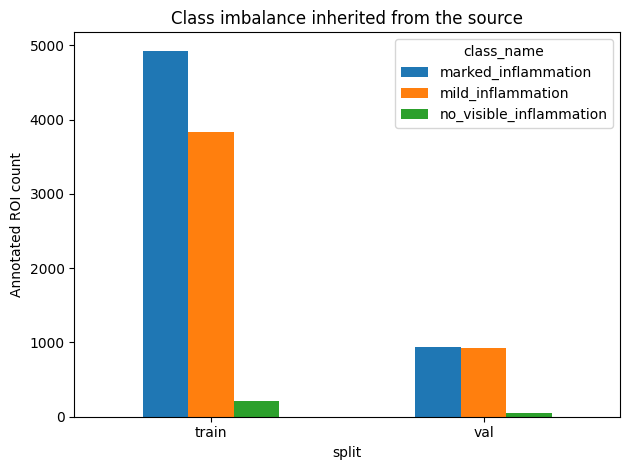

In [4]:
frame, receipt = prepare_rois(DATASET, ROOT / "data/manifests", OUTPUT,
                              ROOT / "src/configs/roi.json", workers=8)
display(pd.Series(receipt, name="Verified preparation receipt"))
display(frame.head())
counts = pd.crosstab(frame["split"], frame["class_name"])
display(counts)
print("Derived images:", len(frame) * 2, "from parents:", frame.parent_id.nunique())
print("Native ROI width/height distribution in prepared 1280-edge source pixels:")
display(frame.groupby(["split", "class_name"])[["box_width", "box_height"]].quantile([.1, .5, .9]))
counts.plot.bar(rot=0, ylabel="Annotated ROI count", title="Class imbalance inherited from the source")
plt.tight_layout(); plt.savefig(REPORT / "roi_class_counts.png", dpi=150); plt.show()

## 3. Inspect paired examples

Select a small and large training ROI per class deterministically. These are quality-control examples,
not independent patients or model-selected errors. Red shows the local box; blue shows context bounds.
Inspect the native ROI size before interpreting 224-pixel crops: resizing does not add image information.

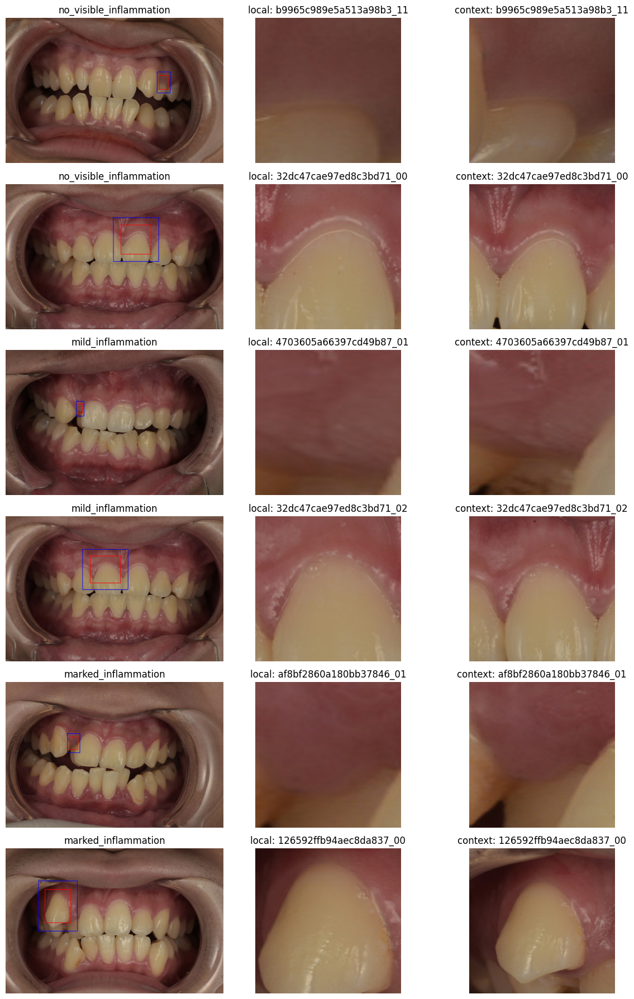

In [5]:
examples = []
for class_id in [0, 1, 2]:
    subset = frame[(frame.split == "train") & (frame.class_id == class_id)].copy()
    subset["area"] = subset.box_width * subset.box_height
    examples.extend(subset.sort_values(["area", "crop_id"]).iloc[[0, -1]].to_dict("records"))
fig, axes = plt.subplots(len(examples), 3, figsize=(12, 3 * len(examples)))
for i, row in enumerate(examples):
    with Image.open(DATASET / row["image_path"]) as im:
        parent = im.convert("RGB")
    draw = ImageDraw.Draw(parent)
    draw.rectangle(json.loads(row["context_bounds"]), outline="blue", width=3)
    draw.rectangle(json.loads(row["local_bounds"]), outline="red", width=3)
    axes[i, 0].imshow(parent); axes[i, 0].set_title(row["class_name"])
    for j, view in enumerate(["local", "context"], 1):
        with Image.open(OUTPUT / row[f"{view}_path"]) as im:
            axes[i, j].imshow(im.copy())
        axes[i, j].set_title(f"{view}: {row['crop_id']}")
    for ax in axes[i]: ax.axis("off")
fig.tight_layout(); fig.savefig(REPORT / "paired_roi_examples.png", dpi=120); plt.show()

## 4. Interpretation and next gate

Class imbalance and low-resolution source ROIs can affect minority-class grading.
Ground-truth crops quantify classification with known localization; final comparison must also use
predicted detector boxes and count missed proposals. A refiner cannot recover regions the detector misses.
Use macro-F1 as the primary ROI screening metric, report every class's recall, and keep test closed.
Do not combine CNN accuracy and detector mAP in one numerical ranking.

Notebook 06 will implement scratch CNN, scratch ResNet18 and ImageNet-initialized ResNet18.
Pretraining, architecture and any later context/ordinal change must be distinct experiments.
Measure 2–3 epochs before scheduling full tracks; do not reuse detector throughput estimates for ROI training.

In [6]:
minority = classes[classes.class_name == "no_visible_inflammation"]
conclusion = {
    "protocol": config["protocol"], "roi_rows": len(frame), "view_files": 2 * len(frame),
    "parents": int(frame.parent_id.nunique()), "splits": sorted(frame.split.unique().tolist()),
    "test_images_opened": receipt["test_images_opened"],
    "parent_split_sha256": receipt["signature"]["parent_splits_sha256"],
    "manifest_sha256": receipt["manifest_sha256"],
    "validation_minority_instances": minority.instances.tolist(),
    "limitations": ["Per-instance detection error attribution is pending prediction export",
                    "Correlated crops are not independent patients", "No real phone generalization evidence"],
    "next": "Implement notebook 06 and benchmark ROI classification throughput on Kaggle T4 x2"
}
from dentalselfie.research import write_json
write_json(REPORT / "conclusion.json", conclusion)
display(pd.Series(conclusion, name="Executed conclusion"))

protocol                                                   gingival-roi-context-v1
roi_rows                                                                     10889
view_files                                                                   21778
parents                                                                        907
splits                                                                [train, val]
test_images_opened                                                               0
parent_split_sha256              17951a893d64d81ad5d8318abac5fb004c791cc3b411d0...
manifest_sha256                  8ed4c05240a2d23e6c254ee74adf13af48ff45a4418f1e...
validation_minority_instances                                             [49, 49]
limitations                      [Per-instance detection error attribution is p...
next                             Implement notebook 06 and benchmark ROI classi...
Name: Executed conclusion, dtype: object

## Implementation appendix

The following is the actual shared module used above. It is displayed for review instead of maintaining
a second implementation in this notebook.

In [7]:
from IPython.display import Code
import dentalselfie.roi as roi_module
display(Code(inspect.getsource(roi_module), language="python"))

"""Hash-verified paired gingival crops, derived without changing parent splits."""
from __future__ import annotations

import json
import math
import re
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import pandas as pd
from PIL import Image

from .acquire import digest
from .research import write_json


def pixel_box(values, width, height):
    """Validate YOLO centre/size values; return a pixel rectangle without clipping."""
    x, y, w, h = map(float, values)
    if not all(math.isfinite(v) for v in (x, y, w, h)) or w <= 0 or h <= 0:
        raise ValueError("Non-finite or empty box")
    box = ((x - w / 2) * width, (y - h / 2) * height,
           (x + w / 2) * width, (y + h / 2) * height)
    if box[0] < -1e-6 or box[1] < -1e-6 or box[2] > width + 1e-6 or box[3] > height + 1e-6:
        raise ValueError("Original annotation exceeds image bounds; do not silently clip")
    return box


def view_bounds(box, multiplier=1.0):
    if multiplier < 1:
        raise ValueError("Context multiplier must be at least one")
    x0, y0, x1, y1 = box
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    half_w, half_h = (x1 - x0) * multiplier / 2, (y1 - y0) * multiplier / 2
    return (math.floor(cx - half_w), math.floor(cy - half_h),
            math.ceil(cx + half_w), math.ceil(cy + half_h))


def padded_view(image, bounds, size, fill):
    """Explicit constant padding for derived views; source geometry stays intact."""
    x0, y0, x1, y1 = bounds
    if x1 <= x0 or y1 <= y0:
        raise ValueError("Empty derived view")
    canvas = Image.new("RGB", (x1 - x0, y1 - y0), tuple(fill))
    intersection = (max(0, x0), max(0, y0), min(image.width, x1), min(image.height, y1))
    if intersection[2] > intersection[0] and intersection[3] > intersection[1]:
        canvas.paste(image.crop(intersection), (intersection[0] - x0, intersection[1] - y0))
    padding = (max(0, -x0), max(0, -y0), max(0, x1 - image.width), max(0, y1 - image.height))
    return canvas.resize((size, size), Image.Resampling.BILINEAR), padding


def prepare_rois(dataset: Path, manifests: Path, output: Path, config_path: Path, workers=8):
    """Reusable locally and on Kaggle's prepared gum dataset; train/val only."""
    config = json.loads(config_path.read_text(encoding="utf-8"))
    if config["splits"] != ["train", "val"]:
        raise ValueError("This stage may process train/validation only")
    split_path, lock_path = manifests / "gum.splits.csv", manifests / "gum.lock.json"
    lock = json.loads(lock_path.read_text(encoding="utf-8"))
    if digest(split_path) != lock["splits_sha256"]:
        raise ValueError("Parent split hash differs from its lock")
    parents = pd.read_csv(split_path, dtype={"sample_id": str})
    if parents.groupby("group_id")["split"].nunique().max() != 1:
        raise ValueError("Parent groups cross splits")
    selected = parents[parents.split.isin(config["splits"])].copy()
    signature = {"protocol": config["protocol"], "config_sha256": digest(config_path),
                 "parent_splits_sha256": digest(split_path), "parent_lock_sha256": digest(lock_path)}
    receipt_path = output / "receipt.json"
    if output.exists() and any(output.iterdir()):
        if not receipt_path.is_file():
            raise ValueError("Existing ROI output is incomplete; preserve it and select a fresh output directory")
        receipt = json.loads(receipt_path.read_text(encoding="utf-8"))
        if receipt["signature"] != signature or digest(output / "manifest.csv") != receipt["manifest_sha256"]:
            raise ValueError("Existing ROI protocol or manifest differs")
        for parent in selected.to_dict("records"):
            image = dataset / "images" / parent["split"] / f"{parent['sample_id']}.jpg"
            label = dataset / "labels" / parent["split"] / f"{parent['sample_id']}.txt"
            if digest(image) != parent["sha256"] or digest(label) != parent["label_sha256"]:
                raise ValueError("Parent checksum mis